In [1]:
import matplotlib.pyplot as plt
import h5py
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from datetime import datetime
import os as os 
import numpy as np
import cmocean
import netCDF4 as nc
from cartopy.feature import LAND
from cartopy.feature import ShapelyFeature
import xarray as xr
import geopandas as gpd
import os as os 
import scipy
import cfgrib
# import fonctions as funcs

#For TOEddies
import sys
sys.path.insert(1, '\\TOEeddies\\TOEddies_WHIRLS')
import pyTOEddies_functions as f
import class_EDDIES as ed
import pandas as pd
from pathlib import Path
from datetime import datetime, timedelta
from pyproj import Geod
import numpy as np
import matplotlib.lines as mlines
from matplotlib.patches import FancyArrowPatch
from tools import *

In [2]:
dir_data = "/Volumes/science/MD252_WHIRLS/REP/data/"
dir_figures = "/Volumes/science/MD252_WHIRLS/REP/figures/"

dir_adcp = dir_data + "SADCP/WHIRLS_NB150_TOT_osite.nc"

dir_eddies = dir_data + f"Eddies/"
save_fig = dir_figures + f"/ADCP/"

adt_daily_dir = dir_data + "daily_adt/"

fname_bathy = dir_data + "bathymetry/etopo2.nc"

In [3]:
path_nav = "/Volumes/science/MD252_WHIRLS/NAV/"
files = sorted(os.listdir(path_nav))


In [4]:
##### POSITION VARIABLES #####
jet = False
cyc = False
anti = True
if jet:
    lon_min, lon_max, lat_min, lat_max = 10, 14.5, -41, -36
    pos_west,pos_east,pos_south,pos_north  = 10, 14.5, -41,-36  #Reset the area
if cyc:
    lon_min, lon_max, lat_min, lat_max = 11, 16, -37, -35
    pos_west,pos_east,pos_south,pos_north  = 11, 16, -37,-35  #Reset the area
if anti:
    lon_min, lon_max, lat_min, lat_max = 9, 13.5, -39, -35
    pos_west,pos_east,pos_south,pos_north  = 9, 13.5, -39,-35  #Reset the area
ft=10

# proj = ccrs.Mercator(central_longitude=(pos_south + pos_north)//2,min_latitude=pos_south+3,max_latitude=pos_north+3)
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent

In [5]:
daily_adt_files = sorted(os.listdir(adt_daily_dir))
adcp_data = xr.open_dataset(dir_adcp)

In [6]:
uvel_adcp = adcp_data.UVEL_ADCP
vvel_adcp = adcp_data.VVEL_ADCP
wvel_adcp = adcp_data.WVEL_ADCP
lon_adcp = adcp_data.LONGITUDE
lat_adcp = adcp_data.LATITUDE
depth_adcp = adcp_data.DEPH

ref_dat = adcp_data.REFERENCE_DATE_TIME
import numpy as np

ref = np.datetime64('1950-01-01T00:00:00')
t_adcp = adcp_data.JULD_ADCP
t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')
adcp_data['time'] = t_adcp 

/var/folders/08/g_gjz7kj0db8g7wf0vbs2mjw0000gn/T/ipykernel_38243/2138320484.py:13: UserWarning: Converting non-nanosecond precision timedelta values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  t_adcp = ref + (t_adcp * 86400).astype('timedelta64[s]')


In [7]:
##### BATHYMETRY #####
bathymetry_data = xr.open_dataset(fname_bathy)
land_feature = cfeature.NaturalEarthFeature(
    category='physical',
    name='land',
    scale='10m',
    edgecolor='black',
    facecolor='gray'
)

# Extract relevant variables (e.g., longitude, latitude, depth)
lon = bathymetry_data['lon']
lat = bathymetry_data['lat']
depth = bathymetry_data['topo']
LON = bathymetry_data['lon']
LAT = bathymetry_data['lat']
depth = bathymetry_data['topo']
lon_subset = LON.sel(lon=slice(lon_min, lon_max))
lat_subset = LAT.sel(lat=slice(lat_min, lat_max))
depth_subset = depth.sel(lon=slice(lon_min, lon_max), lat=slice(lat_min, lat_max))


In [8]:
new_adcp = xr.Dataset(
    data_vars={
        "uvel_adcp": (("time", "depth"), uvel_adcp.values),
        "vvel_adcp": (("time", "depth"), vvel_adcp.values),
        "wvel_adcp": (("time", "depth"), wvel_adcp.values),
        "lon_adcp": (("time"), lon_adcp.values),
        "lat_adcp": (("time"), lat_adcp.values),
    },
    coords={
        "time": t_adcp.values,
        "depth": depth_adcp.values,
    },
)

In [9]:
x_dist = along_track_distance(
    new_adcp.lon_adcp.values,
    new_adcp.lat_adcp.values
)

In [10]:
cyclone_data = {"n_eddy": 16, "x_min_adcp": 400, "x_max_adcp": 600, "date": "2026-07-01", "center": True}
jet_data = {"n_eddy": 16, "x_min_adcp": 400, "x_max_adcp": 720, "date": "2026-07-01", "center": True}
anti_cyclone_data1 = {"n_eddy": 13, "x_min_adcp": 600, "x_max_adcp": 725, "date": "2026-07-01", "center": False}
anti_cyclone_data2 = {"n_eddy": 12, "x_min_adcp": 760, "x_max_adcp": 840, "date": "2026-07-02", "center": True}
anti_cyclone_data3 = {"n_eddy": 12, "x_min_adcp": 860, "x_max_adcp": 950, "date": "2026-07-02", "center": False}
adcp_map = {"Cyclone": cyclone_data, "Anticyclone Cross1": anti_cyclone_data1, "Anticyclone Cross2": anti_cyclone_data2, "Anticyclone Cross3": anti_cyclone_data3}

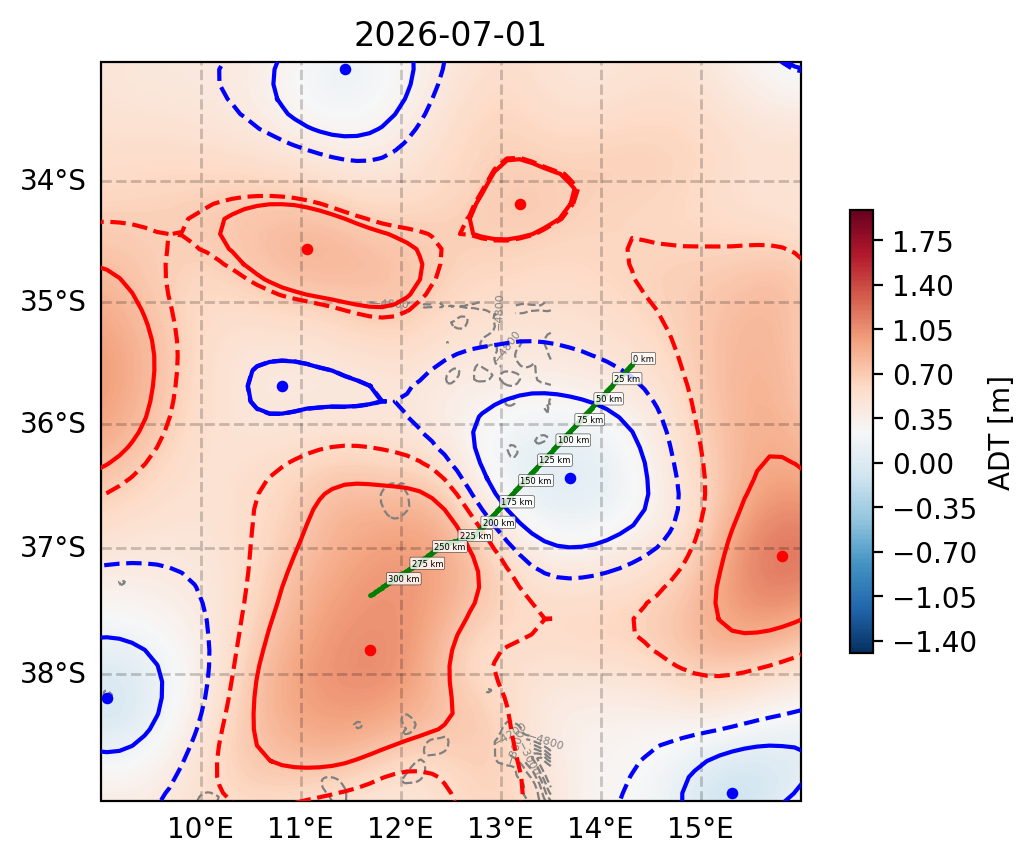

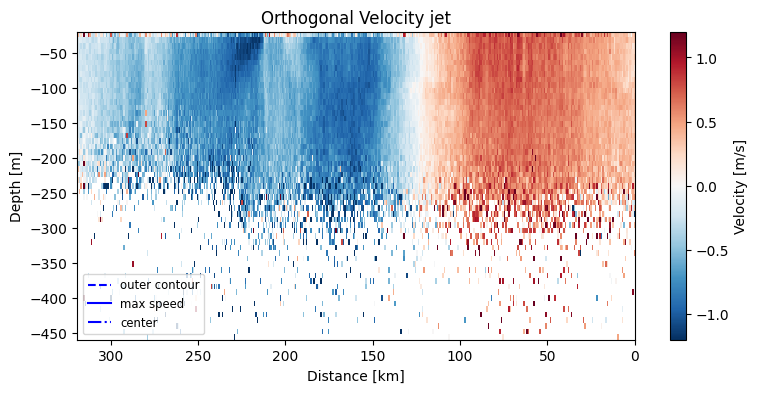

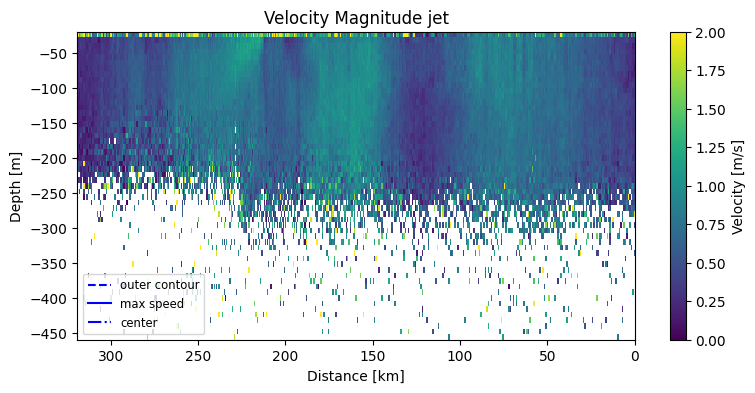

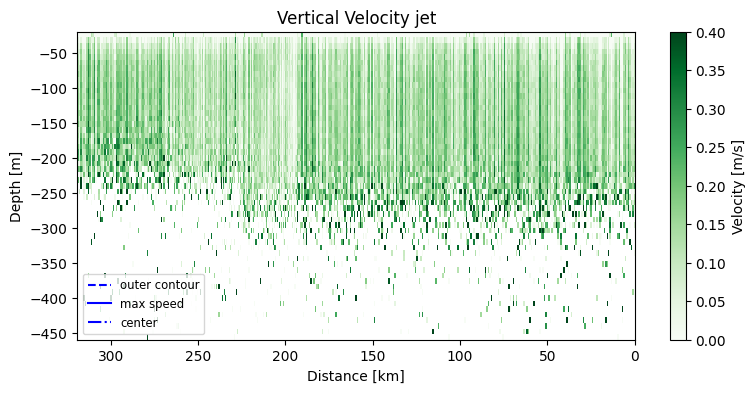

In [11]:
lon_min, lon_max, lat_min, lat_max = 9, 16, -39, -33
pos_west,pos_east,pos_south,pos_north  = 9, 16, -39,-33
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent


x_min_cyc = jet_data["x_min_adcp"]
x_max_cyc = jet_data["x_max_adcp"]
curr_time_eddy = jet_data["date"]


curr_eddies = dir_eddies + curr_time_eddy
anti, cyc = load_eddies(curr_eddies)

file_adt = f"{curr_time_eddy}_cmems_data.nc"
sat = load_satellite(adt_daily_dir + file_adt)



dist_mask = get_x_dist_mask(new_adcp, x_dist, x_min_cyc, x_max_cyc)

curr_adcp = new_adcp.isel(time=dist_mask)
curr_xs = x_dist[dist_mask]


v_orth = orthogonal_velocity(
    curr_adcp,
    curr_xs
)
adcp_mag = velocity_magnitude(curr_adcp.uvel_adcp.values, curr_adcp.vvel_adcp.values)

x = curr_xs / 1000

x_plot = x - x[0]


plot_adt_map_for_adcp(
    sat,
    curr_adcp.lon_adcp.values,
    curr_adcp.lat_adcp.values,
    anti,
    cyc,
    extent,
    curr_time_eddy,
    proj,
    crs,
    ft,
    -1.5,
    2,
    lon_subset,
    lat_subset,
    depth_subset,
    x_plot,
    dx=25)

plt.savefig(save_fig + "jet_map.png")      
plot_adcp_section(
    curr_adcp,               # only used for depth?
    v_orth,
    x_plot,
    f"Orthogonal Velocity jet",
    -1.2,
    1.2,
    cmap="RdBu_r",
)
plt.savefig(save_fig + "jet_v_ortho.png")
plot_adcp_section(
    curr_adcp,               # only used for depth?
    adcp_mag,
    x_plot,
    f"Velocity Magnitude jet",
    0,
    2,
)
plt.savefig(save_fig + "jet_v_mag.png")

plot_adcp_section(
    curr_adcp,               # only used for depth?
    curr_adcp.wvel_adcp.values,
    x_plot,
    f"Vertical Velocity jet",
    0,
    0.4,
    cmap="Greens",
)
plt.savefig(save_fig + "jet_w_vel.png")

In [12]:
pirouettes = [(725, 760), (840, 860)]

In [13]:
for pirouette in pirouettes:
    x1, x2 = pirouette
    new_adcp, x_dist = cut_adcp(new_adcp, x1, x2, x_dist)
adcp_section = new_adcp

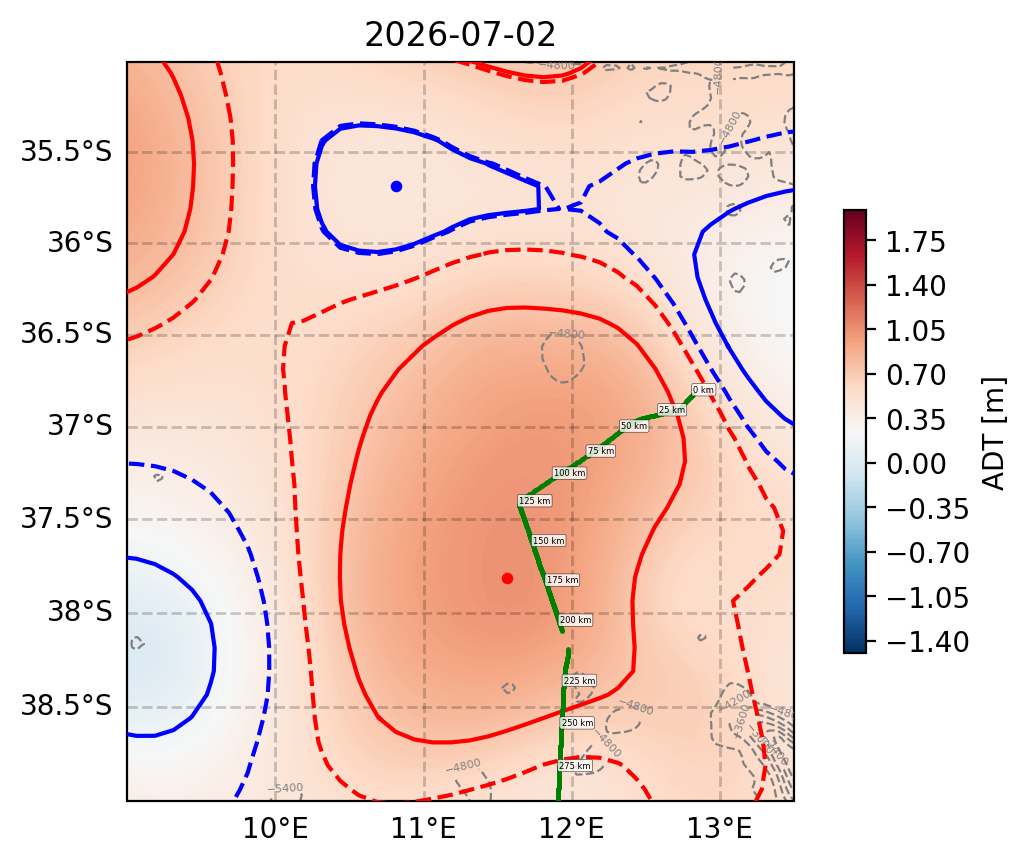

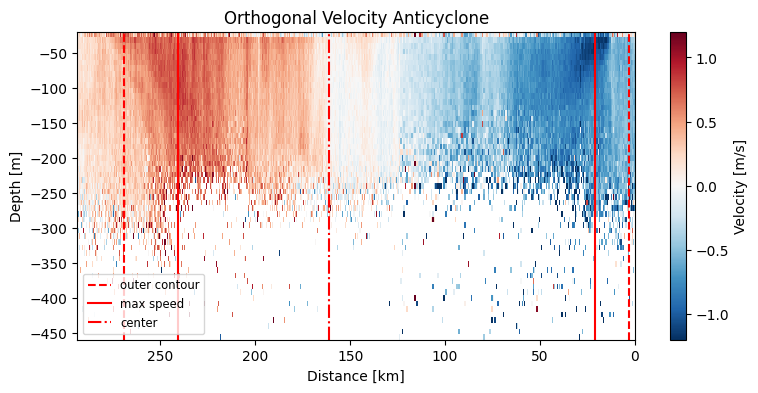

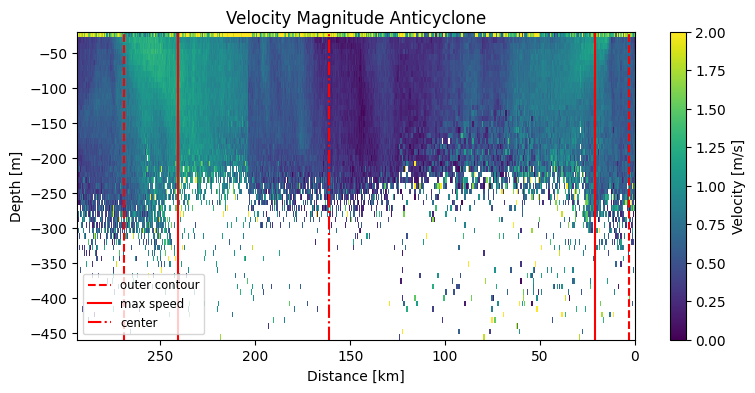

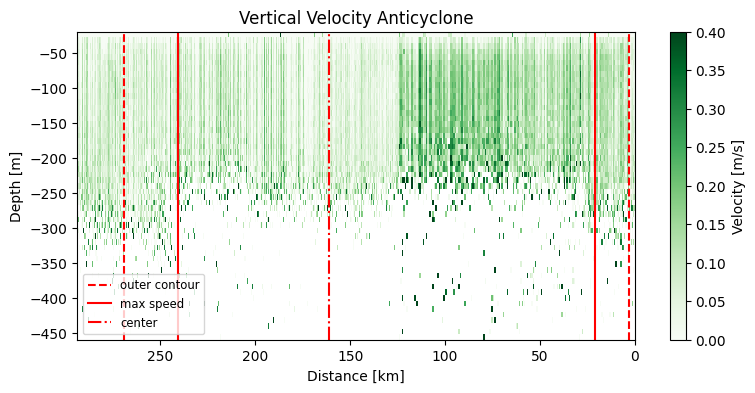

In [14]:
lon_min, lon_max, lat_min, lat_max = 9, 13.5, -39, -35
pos_west,pos_east,pos_south,pos_north  = 9, 13.5, -39,-35 
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent
sections = []

keys = ["Anticyclone Cross1", "Anticyclone Cross2", "Anticyclone Cross3"]
v_orth_all = []
v_mag_all = []
x_all = []

results_ms_all = []
results_oc_all = []
results_cent = []

offset = 0
gap = 10      # km between sections

dist_masks = []
w_vel_all = []
for key in keys:
    curr_cyc = adcp_map[key]
    n_eddy_cyc = curr_cyc["n_eddy"]
    x_min_cyc = curr_cyc["x_min_adcp"]
    x_max_cyc = curr_cyc["x_max_adcp"]
    curr_time_eddy = curr_cyc["date"]
    cent = curr_cyc["center"]

    curr_eddies = dir_eddies + curr_time_eddy
    anti, cyc = load_eddies(curr_eddies)

    file_adt = f"{curr_time_eddy}_cmems_data.nc"
    sat = load_satellite(adt_daily_dir + file_adt)

    eddies = anti if "Anti" in key else cyc

    dist_mask = get_x_dist_mask(new_adcp, x_dist, x_min_cyc, x_max_cyc)
    dist_masks.append(dist_mask)

    curr_adcp = new_adcp.isel(time=dist_mask)
    curr_xs = x_dist[dist_mask]

    results_oc = get_eddy_adcp_intersections(
        eddies["outcontour"],
        n_eddy_cyc,
        curr_adcp,
        curr_xs
    )

    results_ms = get_eddy_adcp_intersections(
        eddies["maxspeed"],
        n_eddy_cyc,
        curr_adcp,
        curr_xs
    )

    if cent:
        results_cent = determined_x_dist_of_center(
            eddies["centers"],
            n_eddy_cyc,
            curr_adcp,
            curr_xs
        )
    
    v_orth = orthogonal_velocity(
        curr_adcp,
        curr_xs
    )
    adcp_mag = velocity_magnitude(curr_adcp.uvel_adcp.values, curr_adcp.vvel_adcp.values)

    x = curr_xs / 1000

    v_orth_all.append(v_orth)
    v_mag_all.append(adcp_mag)
    x_all.append(x)

    results_ms_all.extend(results_ms)
    results_oc_all.extend(results_oc)

    if results_cent is not None:
        results_cent_all = results_cent

    sections.append({
        "x": x,
        "lon": curr_adcp.lon_adcp.values,
        "lat": curr_adcp.lat_adcp.values,
        "v_orth": v_orth,
        "w_vel": curr_adcp.wvel_adcp.values,
        "v_mag": adcp_mag,
        "results_ms": results_ms,
        "results_oc": results_oc,
        "results_cent": results_cent
    })


# -----------------------------
# Glue sections together
# -----------------------------

x_plot_list = []
v_orth_plot_list = []
v_mag_plot_list = []
lons_list = []
lats_list = []
results_ms_all = []
results_oc_all = []
results_cent = []
w_vel_all = []
offset = 0


for i in range(len(sections)):
    sec = sections[i]
    x = sec["x"]

    # new x coordinate starting at 0
    x_new = x - x[0] + offset

    x_plot_list.append(x_new)

    v_orth_plot_list.append(sec["v_orth"])
    v_mag_plot_list.append(sec["v_mag"])
    lons_list.append(sec["lon"])
    lats_list.append(sec["lat"])
    w_vel_all.append(sec["w_vel"])

    results_ms_all.extend(
        shift_results(
            sec["results_ms"],
            x[0],
            offset
        )
    )

    results_oc_all.extend(
        shift_results(
            sec["results_oc"],
            x[0],
            offset
        )
    )
    if i == 1:
        sec["results_cent"]["x_dist"]  = sec["results_cent"]["x_dist"]- x[0] + offset
        results_cent = sec["results_cent"]
    # next section starts after this one
    offset = x_new[-1]

# concatenate
x_plot = np.concatenate(x_plot_list)
lon_list = np.concatenate(lons_list)
lat_list = np.concatenate(lats_list)
w_vel_list = np.concatenate(w_vel_all)

v_orth_plot = np.concatenate(
    v_orth_plot_list,
    axis=0
)

v_mag_plot = np.concatenate(
    v_mag_plot_list,
    axis=0
)

# keep your logic
results_ms_all = [
    results_ms_all[0],
    results_ms_all[-1]
]
results_oc_all = [
    results_oc_all[0],
    results_oc_all[-1]
]

plot_adt_map_for_adcp(
    sat,
    lon_list,
    lat_list,
    anti,
    cyc,
    extent,
    curr_time_eddy,
    proj,
    crs,
    ft,
    -1.5,
    2,
    lon_subset,
    lat_subset,
    depth_subset,
    x_plot,
    dx=25)
plt.savefig(save_fig + "anticyclone_map.png")      
plot_adcp_section(
    new_adcp,               # only used for depth?
    v_orth_plot,
    x_plot,
    f"Orthogonal Velocity Anticyclone",
    -1.2,
    1.2,
    cmap="RdBu_r",
    cyc = False,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=results_cent,
)
plt.savefig(save_fig + "anticyclone_v_ortho.png")
plot_adcp_section(
    new_adcp,               # only used for depth?
    v_mag_plot,
    x_plot,
    f"Velocity Magnitude Anticyclone",
    0,
    2,
    cyc = False,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=results_cent,
)
plt.savefig(save_fig + "anticyclone_v_mag.png")

plot_adcp_section(
    new_adcp,               # only used for depth?
    w_vel_list,
    x_plot,
    f"Vertical Velocity Anticyclone",
    0,
    0.4,
    cmap="Greens",
    cyc = False,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=results_cent,
)
plt.savefig(save_fig + "anticyclone_w_vel.png")

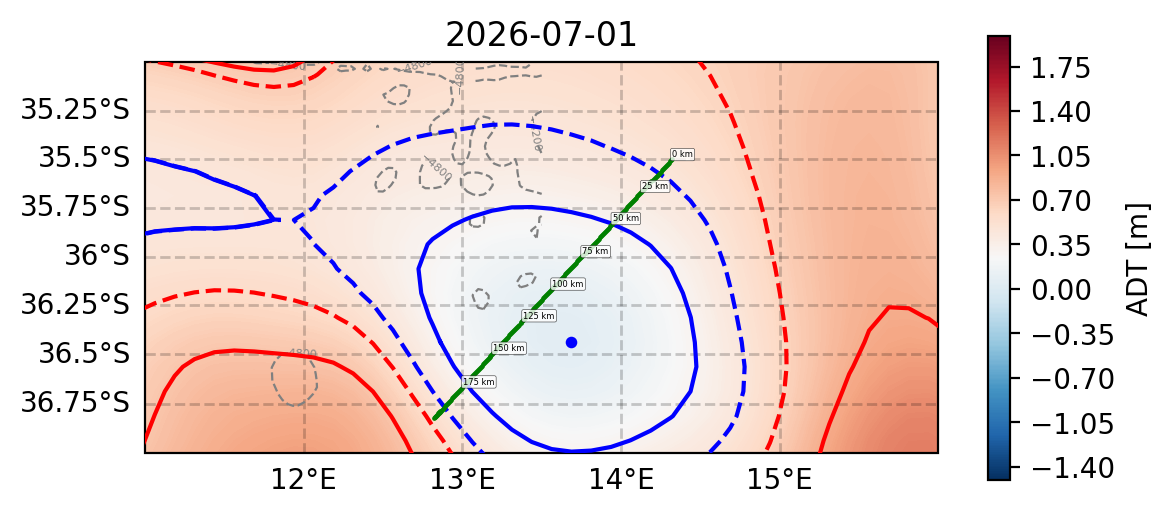

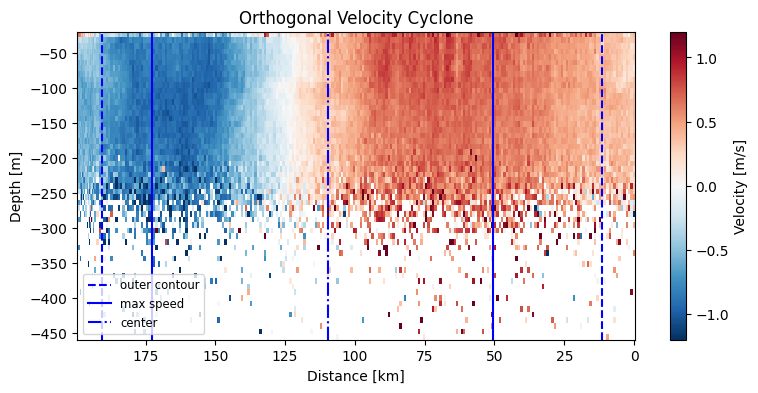

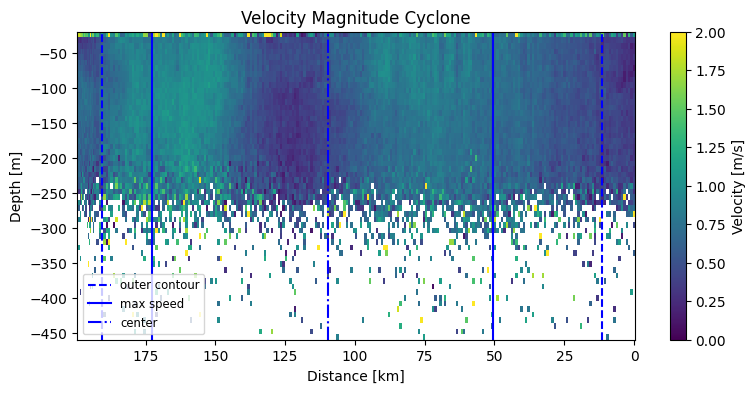

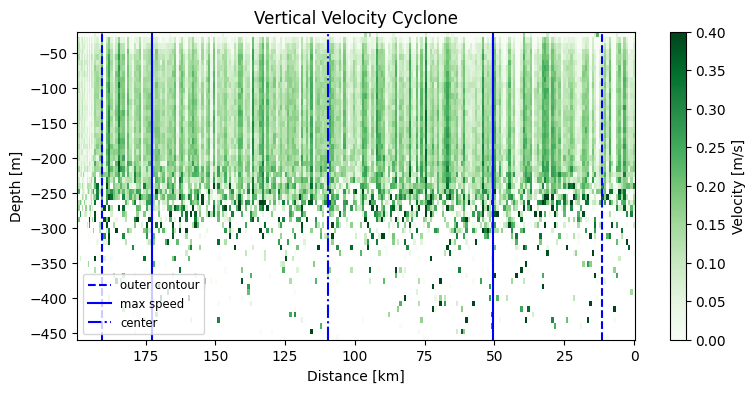

In [15]:
lon_min, lon_max, lat_min, lat_max = 11, 16, -37, -35
pos_west,pos_east,pos_south,pos_north  = 11, 16, -37,-35 
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max)/2)

crs = ccrs.PlateCarree()
extent=[pos_west, pos_east, pos_south, pos_north]
cartmap = proj,crs,extent
sections = []

keys = ["Cyclone"]
v_orth_all = []
v_mag_all = []
x_all = []

results_ms_all = []
results_oc_all = []
results_cent = []

offset = 0
gap = 10      # km between sections

dist_masks = []
for key in keys:
    curr_cyc = adcp_map[key]
    n_eddy_cyc = curr_cyc["n_eddy"]
    x_min_cyc = curr_cyc["x_min_adcp"]
    x_max_cyc = curr_cyc["x_max_adcp"]
    curr_time_eddy = curr_cyc["date"]
    cent = curr_cyc["center"]

    curr_eddies = dir_eddies + curr_time_eddy
    anti, cyc = load_eddies(curr_eddies)

    file_adt = f"{curr_time_eddy}_cmems_data.nc"
    sat = load_satellite(adt_daily_dir + file_adt)

    eddies = anti if "Anti" in key else cyc

    dist_mask = get_x_dist_mask(new_adcp, x_dist, x_min_cyc, x_max_cyc)
    dist_masks.append(dist_mask)

    curr_adcp = new_adcp.isel(time=dist_mask)
    curr_xs = x_dist[dist_mask]

    results_oc = get_eddy_adcp_intersections(
        eddies["outcontour"],
        n_eddy_cyc,
        curr_adcp,
        curr_xs
    )

    results_ms = get_eddy_adcp_intersections(
        eddies["maxspeed"],
        n_eddy_cyc,
        curr_adcp,
        curr_xs
    )

    if cent:
        results_cent = determined_x_dist_of_center(
            eddies["centers"],
            n_eddy_cyc,
            curr_adcp,
            curr_xs
        )
    
    v_orth = orthogonal_velocity(
        curr_adcp,
        curr_xs
    )
    adcp_mag = velocity_magnitude(curr_adcp.uvel_adcp.values, curr_adcp.vvel_adcp.values)


    x = curr_xs / 1000

    v_orth_all.append(v_orth)
    v_mag_all.append(adcp_mag)
    x_all.append(x)

    results_ms_all.extend(results_ms)
    results_oc_all.extend(results_oc)

    if results_cent is not None:
        results_cent_all = results_cent

    sections.append({
        "x": x,
        "lon": curr_adcp.lon_adcp.values,
        "lat": curr_adcp.lat_adcp.values,
        "v_orth": v_orth,
        "v_mag": adcp_mag,
        "results_ms": results_ms,
        "results_oc": results_oc,
        "results_cent": results_cent
    })


# -----------------------------
# Glue sections together
# -----------------------------

x_plot_list = []
v_orth_plot_list = []
v_mag_plot_list = []
lons_list = []
lats_list = []
results_ms_all = []
results_oc_all = []
results_cent = []

offset = 0


for i in range(len(sections)):
    sec = sections[i]
    x = sec["x"]

    # new x coordinate starting at 0
    x_new = x - x[0] + offset

    x_plot_list.append(x_new)

    v_orth_plot_list.append(sec["v_orth"])
    v_mag_plot_list.append(sec["v_mag"])
    lons_list.append(sec["lon"])
    lats_list.append(sec["lat"])

    results_ms_all.extend(
        shift_results(
            sec["results_ms"],
            x[0],
            offset
        )
    )

    results_oc_all.extend(
        shift_results(
            sec["results_oc"],
            x[0],
            offset
        )
    )
    sec["results_cent"]["x_dist"]  = sec["results_cent"]["x_dist"]- x[0] + offset
    # next section starts after this one
    offset = x_new[-1]

# concatenate
x_plot = np.concatenate(x_plot_list)
lon_list = np.concatenate(lons_list)
lat_list = np.concatenate(lats_list)
v_orth_plot = np.concatenate(
    v_orth_plot_list,
    axis=0
)

v_mag_plot = np.concatenate(
    v_mag_plot_list,
    axis=0
)

# keep your logic
results_ms_all = [
    results_ms_all[0],
    results_ms_all[-1]
]
results_oc_all = [
    results_oc_all[0],
    results_oc_all[-1]
]


plot_adt_map_for_adcp(
    sat,
    lon_list,
    lat_list,
    anti,
    cyc,
    extent,
    curr_time_eddy,
    proj,
    crs,
    ft,
    -1.5,
    2,
    lon_subset,
    lat_subset,
    depth_subset,
    x_plot,
    dx=25)

plt.savefig(save_fig + "cyclone_map.png")      

plot_adcp_section(
    new_adcp,               # only used for depth?
    v_orth_plot,
    x_plot,
    f"Orthogonal Velocity Cyclone",
    -1.2,
    1.2,
    cmap="RdBu_r",
    cyc = True,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=sec["results_cent"],
)
plt.savefig(save_fig + "cyclone_v_ortho.png")
plot_adcp_section(
    new_adcp,               # only used for depth?
    v_mag_plot,
    x_plot,
    f"Velocity Magnitude Cyclone",
    0,
    2,
    cyc = True,
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=sec["results_cent"],
)
plt.savefig(save_fig + "cyclone_v_mag.png")

plot_adcp_section(
    new_adcp,               # only used for depth?
    curr_adcp.wvel_adcp.values,
    x_plot,
    f"Vertical Velocity Cyclone",
    0,
    0.4,
    cyc = True,
    cmap="Greens",
    results_ms=results_ms_all,
    results_oc=results_oc_all,
    eddy_center_toeddies=sec["results_cent"],
)
plt.savefig(save_fig + "cyclone_w_vel.png")
